In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error   

In [4]:
df = pd.read_csv("uber.csv")
df.head

<bound method NDFrame.head of         Unnamed: 0                            key  fare_amount  \
0         24238194    2015-05-07 19:52:06.0000003          7.5   
1         27835199    2009-07-17 20:04:56.0000002          7.7   
2         44984355   2009-08-24 21:45:00.00000061         12.9   
3         25894730    2009-06-26 08:22:21.0000001          5.3   
4         17610152  2014-08-28 17:47:00.000000188         16.0   
...            ...                            ...          ...   
199995    42598914   2012-10-28 10:49:00.00000053          3.0   
199996    16382965    2014-03-14 01:09:00.0000008          7.5   
199997    27804658   2009-06-29 00:42:00.00000078         30.9   
199998    20259894    2015-05-20 14:56:25.0000004         14.5   
199999    11951496   2010-05-15 04:08:00.00000076         14.1   

                pickup_datetime  pickup_longitude  pickup_latitude  \
0       2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1       2009-07-17 20:04:56 UTC      

In [5]:
df = pd.read_csv("uber.csv")

df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], errors="coerce")
df["hour"] = df["pickup_datetime"].dt.hour

df = df.dropna()

df = df[df["fare_amount"] > 0]

print(df.head())

   fare_amount           pickup_datetime  pickup_longitude  pickup_latitude  \
0          7.5 2015-05-07 19:52:06+00:00        -73.999817        40.738354   
1          7.7 2009-07-17 20:04:56+00:00        -73.994355        40.728225   
2         12.9 2009-08-24 21:45:00+00:00        -74.005043        40.740770   
3          5.3 2009-06-26 08:22:21+00:00        -73.976124        40.790844   
4         16.0 2014-08-28 17:47:00+00:00        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  hour  
0         -73.999512         40.723217                1    19  
1         -73.994710         40.750325                1    20  
2         -73.962565         40.772647                1    21  
3         -73.965316         40.803349                3     8  
4         -73.973082         40.761247                5    17  


In [6]:
X = df[["pickup_longitude", "pickup_latitude",
        "dropoff_longitude", "dropoff_latitude",
        "passenger_count", "hour"]]

y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [7]:
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

predictions = model.predict(X_test)

In [8]:
print("Mean Absolute Error:", mean_absolute_error(y_test, predictions))
print("R2 Score:", r2_score(y_test, predictions))
mae = mean_absolute_error(y_test, predictions)
rmse = mean_squared_error(y_test, predictions) ** 0.5
r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("Accuracy:", r2 * 100, "%")

Mean Absolute Error: 2.1671111460982386
R2 Score: 0.7935898200502343
MAE: 2.1671111460982386
RMSE: 4.381052408707863
R2 Score: 0.7935898200502343
Accuracy: 79.35898200502342 %


In [9]:
ride = pd.DataFrame([{
    "pickup_longitude": -73.98,
    "pickup_latitude": 40.75,
    "dropoff_longitude": -73.99,
    "dropoff_latitude": 40.73,
    "passenger_count": 1,
    "hour": 10
}])

print("Predicted Uber Fare: $", round(model.predict(ride)[0], 2))

Predicted Uber Fare: $ 7.77


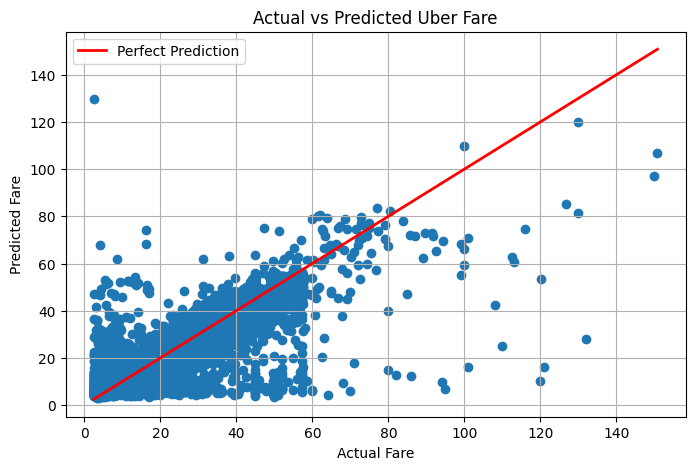

In [42]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, predictions)

# Perfect prediction reference line
a = min(y_test.min(), predictions.min())
b = max(y_test.max(), predictions.max())

plt.plot([a, b], [a, b], color='red', linewidth=2, label='Perfect Prediction')

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Uber Fare")

plt.legend()
plt.grid()
plt.show()